# 4. Real markets: does the deep hedge survive real prices?

Parts 1–3 trained and tested the hedges in the same simulated market, where the model is right by construction. A hedge is only useful if it works on prices nobody simulated.

**Protocol.** We hedge a 3-month at-the-money call on equity indices, with the same 30 trading dates and the same AVaR objective as in part 3. Everything used to build a hedge (volatility, simulator, network, band width) comes from **1990–2009**. The test set is every 63-trading-day window starting between **2010 and November 2026**, one per trading day, rescaled to start at 1. The windows overlap, so they are far from independent; section 4.3 accounts for this.

On real data the AVaR is measured under the historical distribution, drift included. It is a risk charge on the realised loss, not an arbitrage-free price.

In [1]:
import numpy as np
import torch
import matplotlib.pyplot as plt

from deephedge import markets as mk, simulate
from deephedge.benchmarks import band_holdings, delta_holdings, tune_band
from deephedge.losses import avar, avar_objective, hedging_loss
from deephedge.models import PositionHedge
from deephedge.plotting import COLORS, INK, MUTED, GRID, style, save
from deephedge.stats import avar_ratio_interval
from deephedge.train import fit

eps_levels = [0.0, 0.002, 0.005, 0.01]


def train(S_paths, eps, Z=None, seed=0):
    # PositionHedge of part 3; Z holds optional extra inputs (the volatility signal of section 4.5)
    torch.manual_seed(seed)
    model = PositionHedge(S_paths.float(), None if Z is None else Z.float())
    tensors = (S_paths.float(),) if Z is None else (S_paths.float(), Z.float())
    objective = lambda m, s, *z: avar_objective(hedging_loss(m(s, *z), s, eps=eps)[0], m.w, 0.9)
    return fit(model, tensors, objective, progress=False)[0]


def deep_loss(model, S, eps, Z=None):
    with torch.no_grad():
        H = model(S.float(), None if Z is None else Z.float()).double()
    return hedging_loss(H, S, eps=eps)[0]


def band_loss(S, eps, c, sigma):
    return hedging_loss(band_holdings(S, eps, c, sigma), S, eps=eps)[0]


def delta_loss(S, eps, sigma):
    return hedging_loss(delta_holdings(S, sigma), S, eps=eps)[0]


px, log_ret = mk.load_index("sp500")
S_real = mk.test_windows(px)
sigma_cal = mk.calibration_vol(log_ret)
print(f"S&P 500, calibration 1990-2009: annualised volatility {sigma_cal:.4f}")
print(f"test 2010-2026: realised volatility {log_ret[mk.TEST_START:].std() * np.sqrt(252):.4f}, "
      f"{len(S_real):,} overlapping 3-month windows")
print(f"largest 3-month fall {S_real[:, -1].min() - 1:.1%}, largest rise {S_real[:, -1].max() - 1:.1%}")

S&P 500, calibration 1990-2009: annualised volatility 0.1861
test 2010-2026: realised volatility 0.1722, 4,183 overlapping 3-month windows
largest 3-month fall -30.2%, largest rise 39.4%


## 4.1 First attempt: train on Black–Scholes paths

The natural first try: simulate Black–Scholes paths with the 1990–2009 volatility, train the deep hedge and tune the band on them exactly as in part 3, then test on the simulated paths and on the real windows.

In [2]:
S_gbm = simulate.gbm_paths(100_000, seed=10, sigma=sigma_cal).float()
models_gbm = {eps: train(S_gbm, eps) for eps in eps_levels}
c_gbm = {eps: tune_band(S_gbm.double(), eps, sigma_cal) for eps in eps_levels}
S_gbm_test = simulate.gbm_paths(100_000, seed=11, sigma=sigma_cal)

print(f"{'':11s}{'cost':>6s}{'delta':>10s}{'band':>10s}{'deep':>10s}{'deep vs delta':>15s}{'deep vs band':>14s}")
for label, S in [("simulated", S_gbm_test), ("real S&P", S_real)]:
    for eps in eps_levels:
        a = [avar(x, 0.9) for x in (delta_loss(S, eps, sigma_cal), band_loss(S, eps, c_gbm[eps], sigma_cal),
                                    deep_loss(models_gbm[eps], S, eps))]
        print(f"{label:11s}{eps:6.1%}{a[0]:10.5f}{a[1]:10.5f}{a[2]:10.5f}{a[2] / a[0] - 1:15.1%}{a[2] / a[1] - 1:14.1%}")
    print()

             cost     delta      band      deep  deep vs delta  deep vs band


simulated    0.0%   0.04780   0.04780   0.04722          -1.2%         -1.2%


simulated    0.2%   0.05469   0.05389   0.05256          -3.9%         -2.5%


simulated    0.5%   0.06564   0.06212   0.05978          -8.9%         -3.8%


simulated    1.0%   0.08464   0.07476   0.07062         -16.6%         -5.5%

real S&P     0.0%   0.05433   0.05433   0.05539           2.0%          2.0%
real S&P     0.2%   0.06055   0.05912   0.06091           0.6%          3.0%
real S&P     0.5%   0.07027   0.06628   0.06802          -3.2%          2.6%
real S&P     1.0%   0.08744   0.07695   0.07829         -10.5%          1.7%



In the simulated market the deep hedge does what it did in part 3: it beats the band at every cost level, by up to 5.5%. On real prices the ranking flips. The network still beats delta when costs are high, but it loses to the band by 1.7% to 3.0%: the band, tuned on the same Gaussian paths, transfers better. The network learned a policy for a world with Gaussian returns and constant volatility; real returns have fat tails and volatility clusters, and a more flexible policy is more exposed to that mismatch. The fix is not a better network but better training data.

## 4.2 A simulator built from real returns

Instead of Gaussian increments, training paths are glued together from random blocks of 10 consecutive daily returns of 1990–2009. This keeps the fat tails and the short-range volatility clustering of the real market. The returns are de-meaned, so that no hedge can gain by betting on the market's average rise. Network and band are both rebuilt on these paths.

In [3]:
S_boot = mk.block_bootstrap_paths(log_ret[:"2009-12-31"], 100_000, seed=20)
models_boot = {eps: train(S_boot, eps) for eps in eps_levels}
c_boot = {eps: tune_band(S_boot, eps, sigma_cal) for eps in eps_levels}
print("band factors tuned on the bootstrap paths:", c_boot)

real = {}
print(f"\nReal S&P 500, 2010-2026: AVaR_0.9 of the loss")
print(f"{'cost':>6s}{'delta':>10s}{'band':>10s}{'deep (Gaussian)':>17s}{'deep (historical)':>19s}{'vs delta':>10s}{'vs band':>9s}")
for eps in eps_levels:
    real[eps] = {"delta": delta_loss(S_real, eps, sigma_cal), "band": band_loss(S_real, eps, c_boot[eps], sigma_cal),
                 "gaussian": deep_loss(models_gbm[eps], S_real, eps), "historical": deep_loss(models_boot[eps], S_real, eps)}
    a = {k: avar(x, 0.9) for k, x in real[eps].items()}
    print(f"{eps:6.1%}{a['delta']:10.5f}{a['band']:10.5f}{a['gaussian']:17.5f}{a['historical']:19.5f}"
          f"{a['historical'] / a['delta'] - 1:10.1%}{a['historical'] / a['band'] - 1:9.1%}")

band factors tuned on the bootstrap paths: {0.0: 0.0, 0.002: 0.3, 0.005: 0.3, 0.01: 0.3}

Real S&P 500, 2010-2026: AVaR_0.9 of the loss
  cost     delta      band  deep (Gaussian)  deep (historical)  vs delta  vs band
  0.0%   0.05433   0.05433          0.05539            0.05376     -1.1%    -1.1%
  0.2%   0.06055   0.05916          0.06091            0.05792     -4.3%    -2.1%
  0.5%   0.07027   0.06594          0.06802            0.06361     -9.5%    -3.5%
  1.0%   0.08744   0.07660          0.07829            0.07286    -16.7%    -4.9%


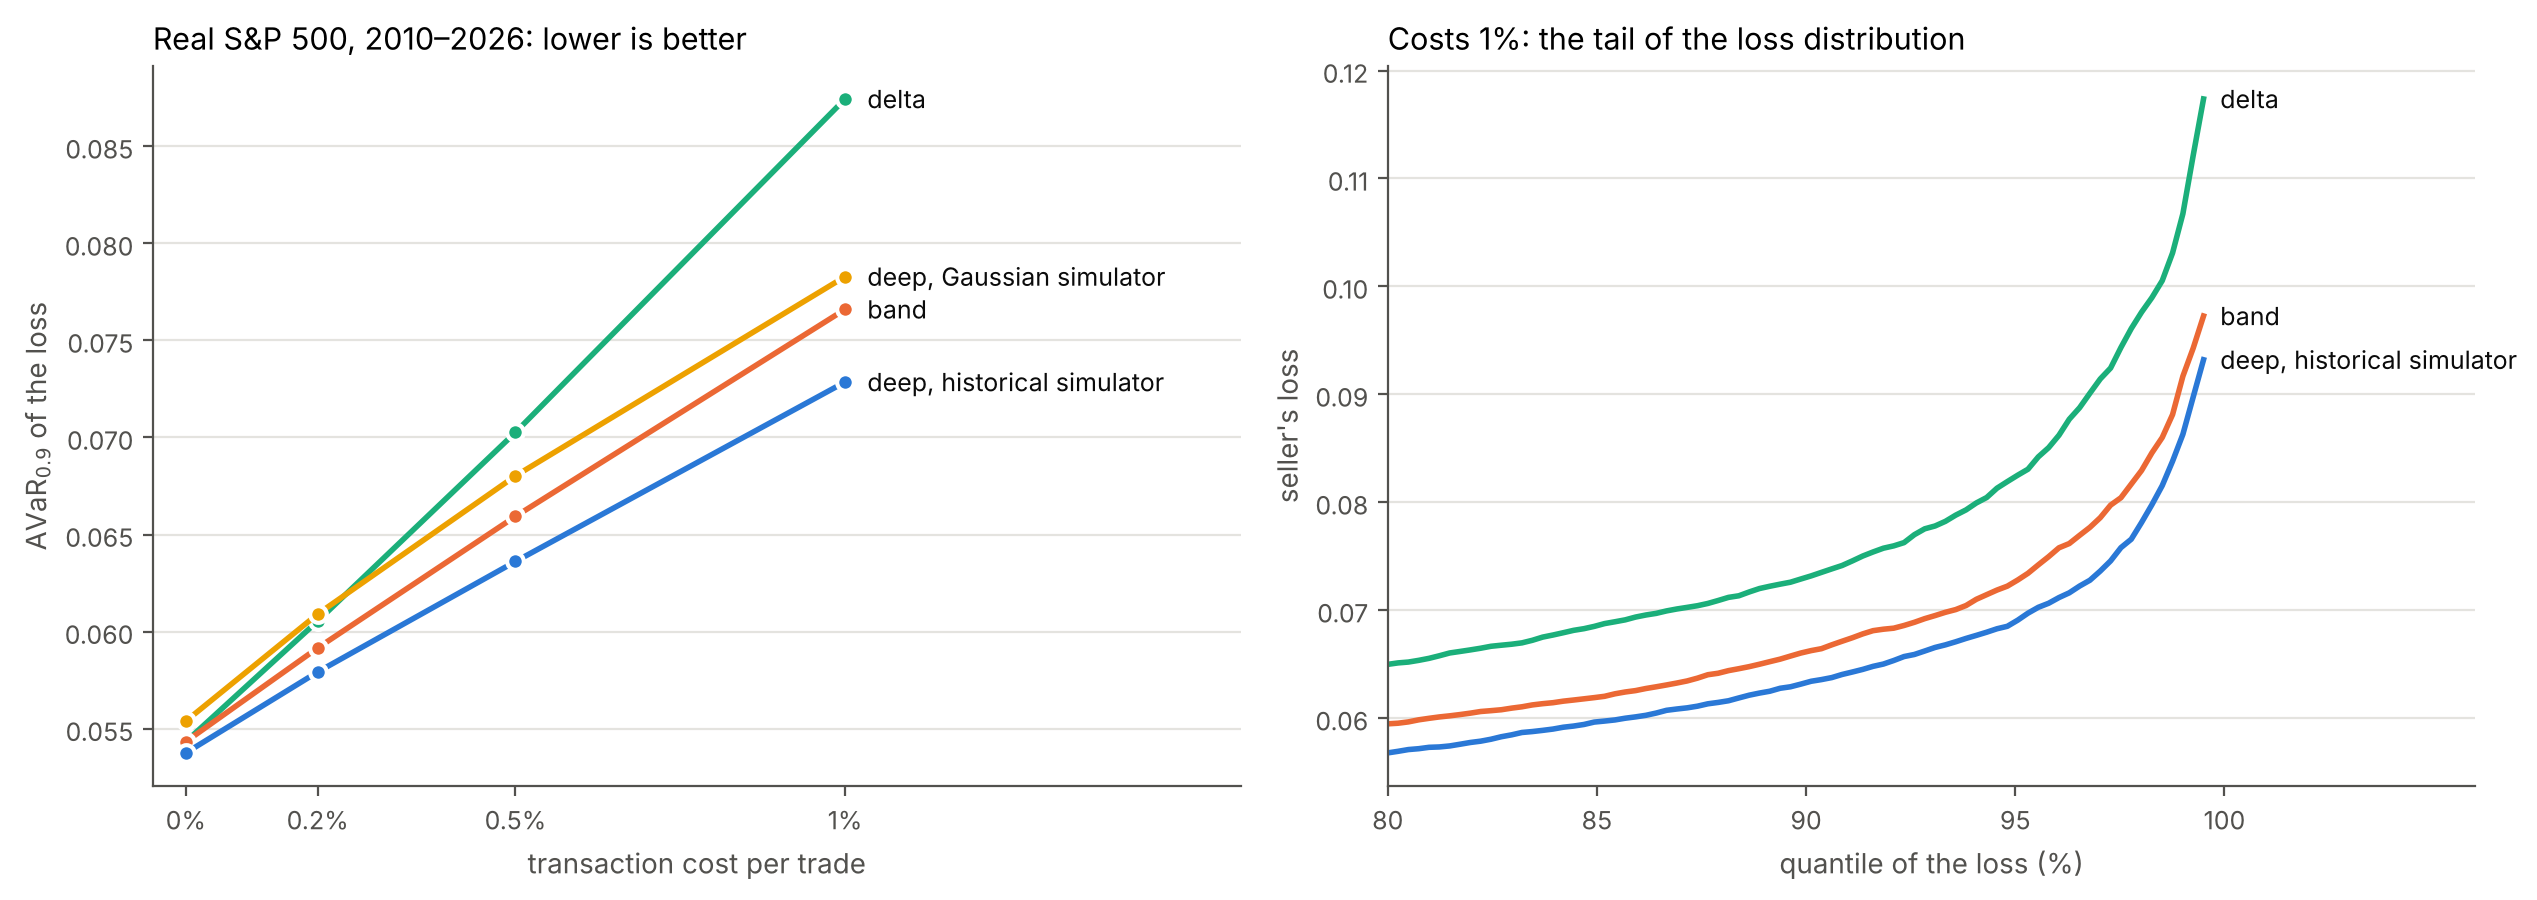

In [4]:
pct = [100 * e for e in eps_levels]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))

ax = axes[0]
for key, label, color in [("delta", "delta", COLORS["delta"]), ("band", "band", COLORS["band"]),
                          ("gaussian", "deep, Gaussian simulator", COLORS["other"]),
                          ("historical", "deep, historical simulator", COLORS["deep"])]:
    y = [avar(real[e][key], 0.9) for e in eps_levels]
    ax.plot(pct, y, color=color, lw=2, marker="o", ms=6, mec="white", mew=1.5)
    ax.annotate(label, (pct[-1], y[-1]), xytext=(8, 0), textcoords="offset points", va="center", fontsize=9, color=INK)
ax.set_xlim(-0.05, 1.6)
ax.set_xticks(pct, [f"{p:g}%" for p in pct])
ax.set_xlabel("transaction cost per trade")
ax.set_ylabel("AVaR$_{0.9}$ of the loss")
ax.set_title("Real S&P 500, 2010–2026: lower is better", loc="left", fontsize=11)
style(ax)

ax = axes[1]
q = np.linspace(0.80, 0.995, 80)
for key, label, color in [("delta", "delta", COLORS["delta"]), ("band", "band", COLORS["band"]),
                          ("historical", "deep, historical simulator", COLORS["deep"])]:
    curve = np.quantile(real[0.01][key].numpy(), q)
    ax.plot(100 * q, curve, color=color, lw=2)
    ax.annotate(label, (100 * q[-1], curve[-1]), xytext=(6, 0), textcoords="offset points", va="center", fontsize=9, color=INK)
ax.set_xlim(80, 106)
ax.set_xticks([80, 85, 90, 95, 100])
ax.set_xlabel("quantile of the loss (%)")
ax.set_ylabel("seller's loss")
ax.set_title("Costs 1%: the tail of the loss distribution", loc="left", fontsize=11)
style(ax)
plt.tight_layout()
save(fig, "part4_sp500")
plt.show()

Trained on historical returns, the deep hedge is the best strategy on the real windows at every cost level: at 1% costs it is 16.7% below delta and 4.9% below the band. The band was re-tuned on the same bootstrap paths, so the comparison is fair. The right panel shows where the gain comes from: the whole upper tail of the loss distribution is lower, not one extreme quantile.

## 4.3 Is the real-data result robust?

Three checks: sub-periods (including and excluding the 2020 crash), statistical uncertainty, and training choices. For the uncertainty, the overlapping windows are resampled in blocks of 63 consecutive windows (one quarter), 2,000 times.

In [5]:
starts = mk.window_dates(px, len(S_real))
covid = torch.tensor(np.asarray((starts >= "2019-11-01") & (starts <= "2020-06-30")))     # windows overlapping Feb-Apr 2020
periods = {"2010-2017": torch.tensor(np.asarray(starts < "2018-01-01")),
           "2018-2026": torch.tensor(np.asarray(starts >= "2018-01-01")),
           "without the 2020 crash": ~covid,
           "2020 crash windows only": covid}

print("(1) Deep hedge (historical simulator) vs band, AVaR_0.9 on sub-periods")
print(f"{'':26s}{'windows':>9s}{'costs 0.5%':>12s}{'costs 1%':>10s}")
for name, mask in periods.items():
    g = [avar(real[e]["historical"][mask], 0.9) / avar(real[e]["band"][mask], 0.9) - 1 for e in [0.005, 0.01]]
    print(f"{name:26s}{int(mask.sum()):9d}{g[0]:12.1%}{g[1]:10.1%}")

print("\n(2) Block bootstrap over time")
print(f"{'':12s}{'gain':>8s}{'95% interval':>20s}{'P(deep better)':>17s}")
for eps in [0.005, 0.01]:
    (lo, hi), p_better = avar_ratio_interval(real[eps]["band"], real[eps]["historical"])
    g = avar(real[eps]["historical"], 0.9) / avar(real[eps]["band"], 0.9) - 1
    print(f"{f'costs {eps:.1%}':12s}{g:8.1%}{f'[{lo:.1%}, {hi:.1%}]':>20s}{p_better:17.1%}")

print("\n(3) Training choices, costs 1%: gain over the band on the full test period")
for block, seed in [(10, 0), (10, 1), (10, 2), (5, 0), (20, 0)]:
    if (block, seed) == (10, 0):
        model, c = models_boot[0.01], c_boot[0.01]
    else:
        S_b = mk.block_bootstrap_paths(log_ret[:"2009-12-31"], 100_000, seed=20, block=block)
        model, c = train(S_b, 0.01, seed=seed), tune_band(S_b, 0.01, sigma_cal)
    g = avar(deep_loss(model, S_real, 0.01), 0.9) / avar(band_loss(S_real, 0.01, c, sigma_cal), 0.9) - 1
    print(f"  blocks of {block:2d} days, seed {seed}: band c = {c:.2f}, gain {g:+.1%}")

(1) Deep hedge (historical simulator) vs band, AVaR_0.9 on sub-periods
                            windows  costs 0.5%  costs 1%
2010-2017                      2013       -0.9%     -3.1%
2018-2026                      2170       -4.6%     -5.8%
without the 2020 crash         4017       -4.3%     -6.5%
2020 crash windows only         166        2.1%      0.2%

(2) Block bootstrap over time
                gain        95% interval   P(deep better)
costs 0.5%     -3.5%       [-7.2%, 0.2%]            96.8%


costs 1.0%     -4.9%      [-9.4%, -0.4%]            98.6%

(3) Training choices, costs 1%: gain over the band on the full test period
  blocks of 10 days, seed 0: band c = 0.30, gain -4.9%


  blocks of 10 days, seed 1: band c = 0.30, gain -5.0%


  blocks of 10 days, seed 2: band c = 0.30, gain -5.3%


  blocks of  5 days, seed 0: band c = 0.25, gain -2.9%


  blocks of 20 days, seed 0: band c = 0.30, gain -5.2%


The gain holds in both halves of the test period and is larger in the second. Its weak spot is the 2020 crash: on the 166 windows that overlap February–April 2020, the network is 0.2% to 2.1% worse than the band.

With overlapping windows the statistical uncertainty is large. At 1% costs the 95% interval, $[-9.4\%, -0.4\%]$, lies entirely below zero; at 0.5% costs it just reaches zero, $[-7.2\%, +0.2\%]$. Two more training seeds and blocks of 20 days give the same gain. Blocks of 5 days give a smaller one ($-2.9\%$), probably because such short blocks keep less of the volatility clustering the simulator is meant to reproduce.

## 4.4 Six indices

The same protocol on five more markets, each with its own data only: volatility and simulator from its 1990–2009 returns, network and band trained on that simulator, test on its 2010–2026 windows.

In [6]:
markets = {"sp500": "S&P 500", "nasdaq100": "Nasdaq 100", "dax": "DAX", "ftse100": "FTSE 100",
           "nikkei225": "Nikkei 225", "hangseng": "Hang Seng"}
scale = []
for name, label in markets.items():
    px_m, r_m = mk.load_index(name)
    S_m, sig_m = mk.test_windows(px_m), mk.calibration_vol(r_m)
    S_b = mk.block_bootstrap_paths(r_m[:"2009-12-31"], 100_000, seed=20)
    for eps in [0.005, 0.01]:
        if name == "sp500":
            model, c = models_boot[eps], c_boot[eps]
        else:
            model, c = train(S_b, eps), tune_band(S_b, eps, sig_m)
        X_delta, X_band, X_deep = delta_loss(S_m, eps, sig_m), band_loss(S_m, eps, c, sig_m), deep_loss(model, S_m, eps)
        (lo, hi), p_better = avar_ratio_interval(X_band, X_deep)
        scale.append(dict(market=label, eps=eps, vol_cal=sig_m, vol_test=r_m[mk.TEST_START:].std() * np.sqrt(252),
                          vs_delta=avar(X_deep, 0.9) / avar(X_delta, 0.9) - 1,
                          vs_band=avar(X_deep, 0.9) / avar(X_band, 0.9) - 1, lo=lo, hi=hi, p=p_better))

print(f"{'':12s}{'vol 90-09':>10s}{'vol 10-26':>10s}{'cost':>6s}{'vs delta':>10s}{'vs band':>9s}{'95% interval':>18s}{'P(better)':>11s}")
for s in scale:
    interval = f"[{s['lo']:.1%}, {s['hi']:.1%}]"
    print(f"{s['market']:12s}{s['vol_cal']:10.3f}{s['vol_test']:10.3f}{s['eps']:6.1%}{s['vs_delta']:10.1%}{s['vs_band']:9.1%}"
          f"{interval:>18s}{s['p']:11.1%}")
for eps in [0.005, 0.01]:
    rows = [s for s in scale if s["eps"] == eps]
    print(f"\ncosts {eps:.1%}: average vs delta {np.mean([s['vs_delta'] for s in rows]):+.1%}, "
          f"vs band {np.mean([s['vs_band'] for s in rows]):+.1%}; significantly better than the band on "
          f"{sum(s['hi'] < 0 for s in rows)} of 6 markets, significantly worse on {sum(s['lo'] > 0 for s in rows)}")

             vol 90-09 vol 10-26  cost  vs delta  vs band      95% interval  P(better)
S&P 500          0.186     0.172  0.5%     -9.5%    -3.5%     [-7.2%, 0.2%]      96.8%
S&P 500          0.186     0.172  1.0%    -16.7%    -4.9%    [-9.4%, -0.4%]      98.6%
Nasdaq 100       0.301     0.209  0.5%     -3.6%    -4.4%    [-7.0%, -1.2%]      99.7%
Nasdaq 100       0.301     0.209  1.0%     -8.7%    -6.3%    [-9.1%, -3.1%]     100.0%
DAX              0.235     0.193  0.5%     -3.2%     0.7%     [-5.2%, 6.4%]      37.1%
DAX              0.235     0.193  1.0%    -10.4%    -1.1%     [-6.7%, 4.5%]      66.8%
FTSE 100         0.183     0.154  0.5%     -9.2%     1.1%     [-2.9%, 5.1%]      28.2%
FTSE 100         0.183     0.154  1.0%    -18.0%     0.0%     [-4.9%, 4.7%]      51.1%
Nikkei 225       0.251     0.219  0.5%    -11.2%    -9.1%   [-15.2%, -2.7%]      99.9%
Nikkei 225       0.251     0.219  1.0%    -15.9%    -9.5%   [-14.6%, -4.1%]     100.0%
Hang Seng        0.274     0.209  0.5%     

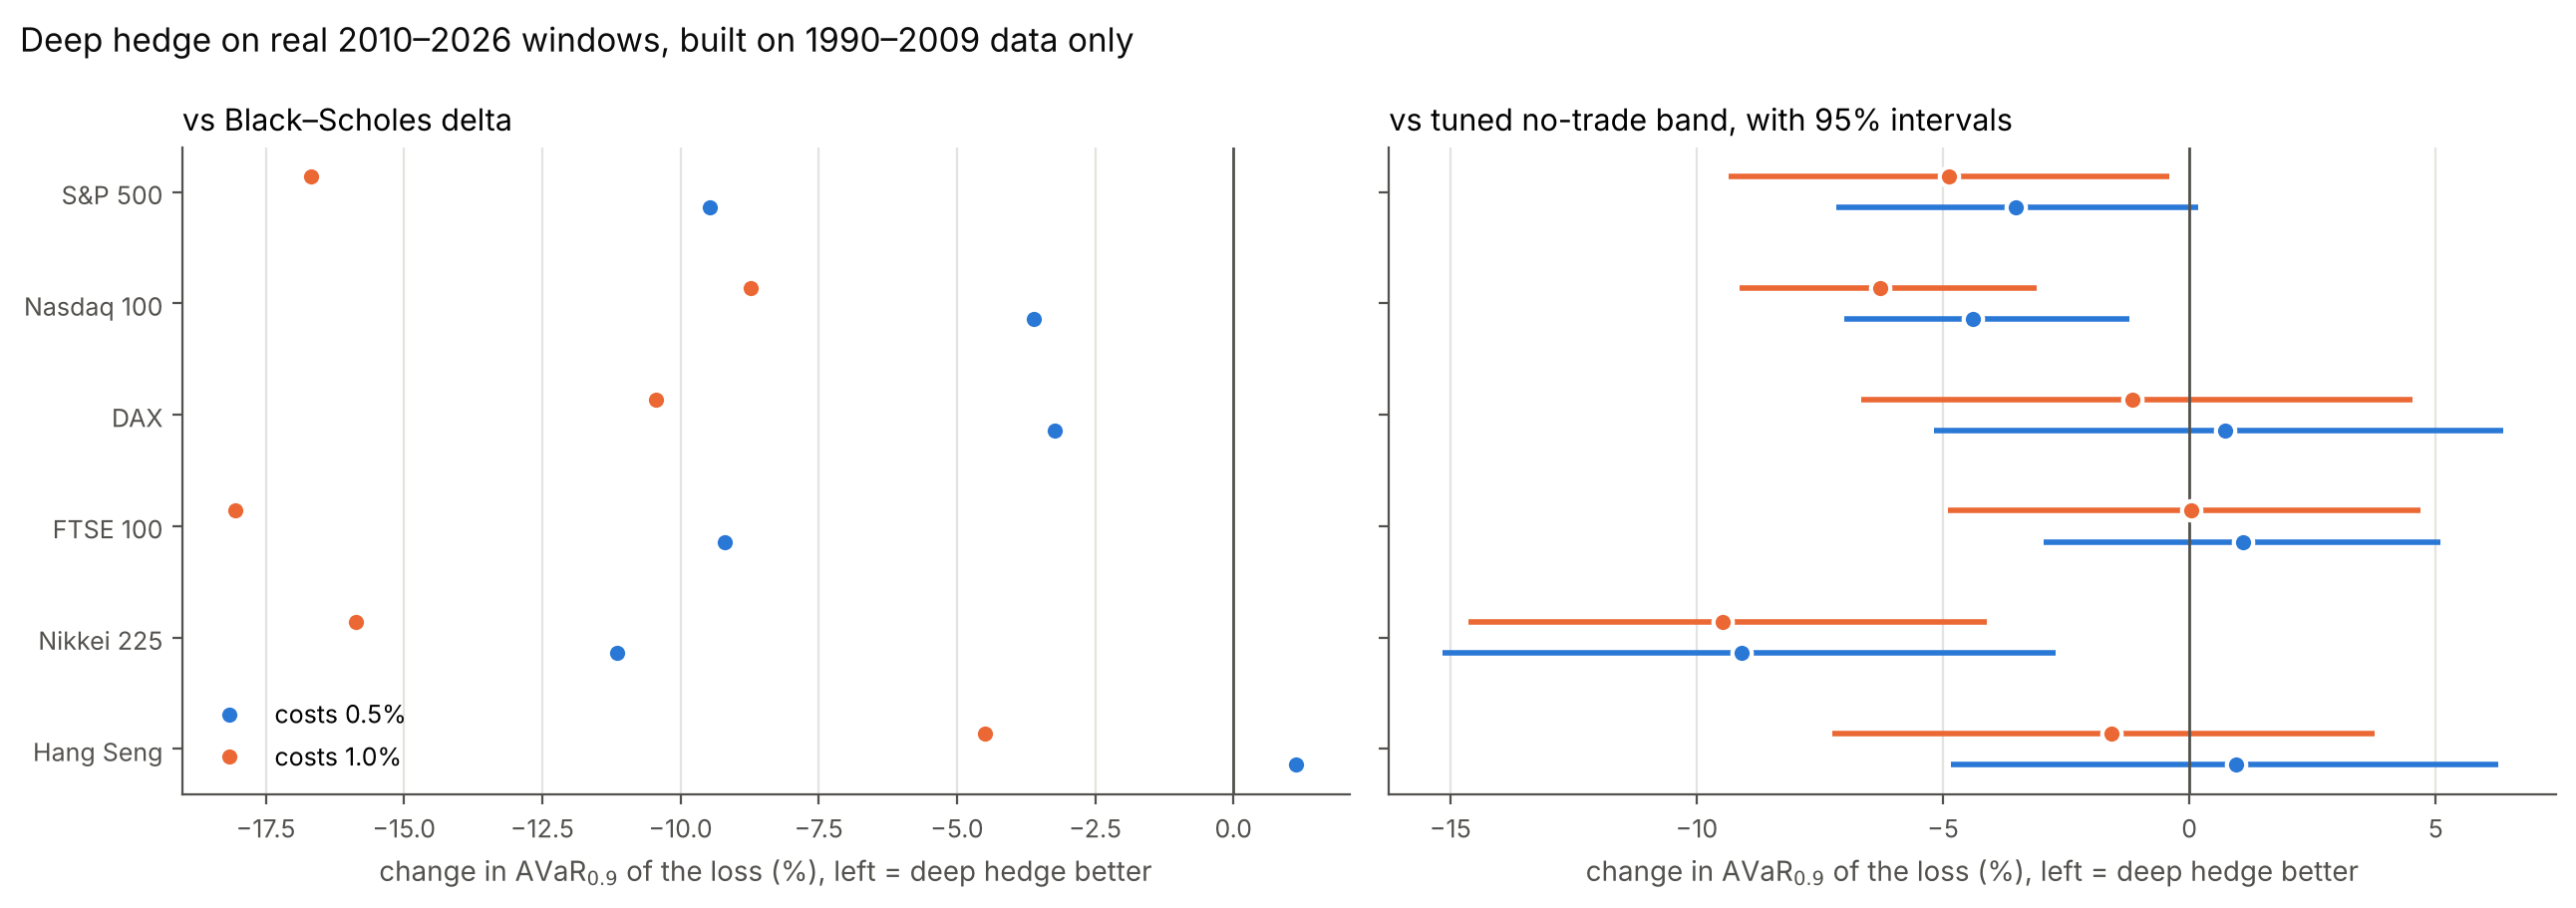

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), sharey=True)
labels = list(markets.values())
y = np.arange(len(labels))[::-1]
for eps, color, dy in [(0.005, COLORS["deep"], -0.14), (0.01, COLORS["band"], 0.14)]:
    rows = [s for s in scale if s["eps"] == eps]
    axes[0].plot([100 * s["vs_delta"] for s in rows], y + dy, "o", color=color, ms=7, mec="white", mew=1.5,
                 label=f"costs {eps:.1%}")
    g = np.array([100 * s["vs_band"] for s in rows])
    lo, hi = np.array([100 * s["lo"] for s in rows]), np.array([100 * s["hi"] for s in rows])
    axes[1].errorbar(g, y + dy, xerr=[g - lo, hi - g], fmt="o", ms=7, color=color, mec="white", mew=1.5,
                     elinewidth=2, capsize=0)
axes[0].set_title("vs Black–Scholes delta", loc="left", fontsize=11)
axes[1].set_title("vs tuned no-trade band, with 95% intervals", loc="left", fontsize=11)
for ax in axes:
    ax.axvline(0, color=MUTED, lw=1)
    ax.set_xlabel("change in AVaR$_{0.9}$ of the loss (%), left = deep hedge better")
    style(ax, grid="x")
axes[0].set_yticks(y, labels)
axes[0].legend(frameon=False, fontsize=9, loc="lower left")
fig.suptitle("Deep hedge on real 2010–2026 windows, built on 1990–2009 data only", x=0.01, ha="left", fontsize=12, color=INK)
plt.tight_layout()
save(fig, "part4_indices")
plt.show()

Against delta the deep hedge is better on every index at 1% costs, by 12.4% on average (from 4.5% on the Hang Seng to 18.0% on the FTSE 100). Against the tuned band the picture is more nuanced: the network is better on average ($-3.9\%$ at 1% costs), significantly better on three markets (S&P 500, Nasdaq 100, Nikkei 225) and never significantly worse, but on the DAX, the FTSE 100 and the Hang Seng the difference is within noise. The Hang Seng at 0.5% costs is the only case where the network does worse than delta (+1.1%).

## 4.5 Volatility regimes

The block bootstrap glues together independent 10-day blocks, so a calm month can follow a panic month at random. In such paths recent volatility says nothing about future volatility, and a network trained on them cannot learn to use it. In real data it does: the volatility of the 20 days before a window predicts the volatility inside it.

We therefore switch to **filtered historical simulation** (Barone-Adesi et al., 1999). A GJR-GARCH(1,1) fitted on 1990–2009 carries the persistence of volatility and the leverage effect (Glosten, Jagannathan & Runkle, 1993); its innovations are resampled from the real standardised residuals, which keeps the fat tails. Each path also gets 20 days of history before $t_0$.

In [8]:
r_cal = log_ret[:"2009-12-31"]
gjr = mk.fit_gjr(r_cal.to_numpy() - r_cal.mean())
persistence = gjr[1] + gjr[2] / 2 + gjr[3]
print(f"GJR-GARCH(1,1) on 1990-2009: a = {gjr[1]:.3f}, g = {gjr[2]:.3f}, b = {gjr[3]:.3f}, persistence {persistence:.4f}, "
      f"half-life of a volatility shock {np.log(0.5) / np.log(persistence):.0f} trading days")

S_fhs, R_fhs = mk.fhs_paths(r_cal, 100_000, seed=30, params=gjr)
R_real = mk.history_windows(log_ret, S_real)
print(f"\nDoes the volatility of the 20 days before t_0 predict the volatility inside the window? (correlation of logs)")
print(f"  real S&P 500, 2010-2026 windows: {mk.vol_persistence(R_real):.2f}")
print(f"  block bootstrap of section 4.2:  {mk.vol_persistence(mk.block_bootstrap_returns(r_cal, 100_000, seed=20)):.2f}")
print(f"  filtered historical simulation:  {mk.vol_persistence(R_fhs):.2f}")

p_cal = px[:"2009-12-31"].to_numpy()
real_cal = np.array([p_cal[s + mk.DAYS] / p_cal[s] for s in range(len(p_cal) - mk.DAYS)])
print(f"\nAgainst the real 1990-2009 3-month windows:")
print(f"  volatility    simulated {np.sqrt(252 * np.mean(R_fhs[:, mk.LOOKBACK:] ** 2)):.3f}   real {sigma_cal:.3f}")
print(f"  1% quantile   simulated {np.quantile(S_fhs[:, -1].numpy(), 0.01) - 1:+.1%}   real {np.quantile(real_cal, 0.01) - 1:+.1%}")
print(f"  99% quantile  simulated {np.quantile(S_fhs[:, -1].numpy(), 0.99) - 1:+.1%}   real {np.quantile(real_cal, 0.99) - 1:+.1%}")

GJR-GARCH(1,1) on 1990-2009: a = 0.004, g = 0.118, b = 0.930, persistence 0.9924, half-life of a volatility shock 90 trading days



Does the volatility of the 20 days before t_0 predict the volatility inside the window? (correlation of logs)
  real S&P 500, 2010-2026 windows: 0.41
  block bootstrap of section 4.2:  -0.00
  filtered historical simulation:  0.66

Against the real 1990-2009 3-month windows:
  volatility    simulated 0.190   real 0.186
  1% quantile   simulated -25.7%   real -24.7%
  99% quantile  simulated +22.2%   real +20.1%


Two deep hedges are trained on these paths, to separate the two changes: the same network as before (inputs $S$ and the current holding), and one with an extra input, the realised volatility of the last 20 trading days, known at the decision date. The band gets the same information: a second band uses the recent volatility for both delta and width.

In [9]:
V_fhs = mk.vol_signal(R_fhs)
V_real = mk.vol_signal(R_real)
logv = lambda V: torch.log(V.float())[..., None]

eps_main = [0.005, 0.01]
models_fhs = {eps: train(S_fhs, eps) for eps in eps_main}
models_vol = {eps: train(S_fhs, eps, Z=logv(V_fhs)) for eps in eps_main}
c_fhs = {eps: tune_band(S_fhs, eps, sigma_cal) for eps in eps_main}
c_rv = {eps: tune_band(S_fhs, eps, V_fhs) for eps in eps_main}
print("band factors, constant volatility:", c_fhs, "| recent volatility:", c_rv)


def all_losses(eps, S, V):
    return {"delta": delta_loss(S, eps, sigma_cal),
            "band": band_loss(S, eps, c_fhs[eps], sigma_cal),
            "band, recent vol": band_loss(S, eps, c_rv[eps], V),
            "deep, 4.2": deep_loss(models_boot[eps], S, eps),
            "deep, FHS": deep_loss(models_fhs[eps], S, eps),
            "deep, FHS + vol": deep_loss(models_vol[eps], S, eps, logv(V))}


X_vol = {eps: all_losses(eps, S_real, V_real) for eps in eps_main}
names = list(X_vol[0.005])
print(f"\nReal S&P 500, 2010-2026: AVaR_0.9 of the loss")
print(f"{'cost':>6s}" + "".join(f"{n:>18s}" for n in names))
for eps in eps_main:
    print(f"{eps:6.1%}" + "".join(f"{avar(x, 0.9):18.5f}" for x in X_vol[eps].values()))

print("\nDeep hedge with the volatility input vs (95% block-bootstrap interval, P(better)):")
for eps in eps_main:
    print(f"  costs {eps:.1%}")
    for ref, why in [("band, recent vol", "best classical hedge, same information"),
                     ("deep, FHS", "same network without the volatility input"),
                     ("deep, 4.2", "deep hedge of section 4.2")]:
        (lo, hi), p_better = avar_ratio_interval(X_vol[eps][ref], X_vol[eps]["deep, FHS + vol"])
        g = avar(X_vol[eps]["deep, FHS + vol"], 0.9) / avar(X_vol[eps][ref], 0.9) - 1
        print(f"    vs {ref:17s}{g:+7.1%}  [{lo:+.1%}, {hi:+.1%}]  {p_better:6.1%}   ({why})")

print("\n2020 crash windows only, AVaR_0.9 relative to the better band:")
for eps in eps_main:
    X = {k: x[covid] for k, x in X_vol[eps].items()}
    best = min(avar(X["band"], 0.9), avar(X["band, recent vol"], 0.9))
    print(f"  costs {eps:.1%}: deep 4.2 {avar(X['deep, 4.2'], 0.9) / best - 1:+.1%}, deep FHS {avar(X['deep, FHS'], 0.9) / best - 1:+.1%}, "
          f"deep FHS + vol {avar(X['deep, FHS + vol'], 0.9) / best - 1:+.1%}")

band factors, constant volatility: {0.005: 0.35, 0.01: 0.4} | recent volatility: {0.005: 0.2, 0.01: 0.25}

Real S&P 500, 2010-2026: AVaR_0.9 of the loss
  cost             delta              band  band, recent vol         deep, 4.2         deep, FHS   deep, FHS + vol
  0.5%           0.07027           0.06657           0.06489           0.06361           0.06405           0.06136
  1.0%           0.08744           0.07759           0.07528           0.07286           0.07307           0.07020

Deep hedge with the volatility input vs (95% block-bootstrap interval, P(better)):
  costs 0.5%
    vs band, recent vol   -5.4%  [-9.6%, -1.8%]  100.0%   (best classical hedge, same information)


    vs deep, FHS          -4.2%  [-8.9%, +0.2%]   96.8%   (same network without the volatility input)
    vs deep, 4.2          -3.5%  [-9.2%, +2.4%]   85.2%   (deep hedge of section 4.2)
  costs 1.0%


    vs band, recent vol   -6.8%  [-9.9%, -3.5%]  100.0%   (best classical hedge, same information)
    vs deep, FHS          -3.9%  [-8.7%, +0.2%]   96.5%   (same network without the volatility input)


    vs deep, 4.2          -3.6%  [-9.2%, +1.5%]   88.9%   (deep hedge of section 4.2)

2020 crash windows only, AVaR_0.9 relative to the better band:
  costs 0.5%: deep 4.2 +0.4%, deep FHS -6.1%, deep FHS + vol -1.2%
  costs 1.0%: deep 4.2 +5.7%, deep FHS -1.5%, deep FHS + vol +0.8%


The filtered simulation keeps volatility persistent (correlation 0.66, against 0.41 in the real test windows and none in the block bootstrap) and matches the volatility and the tails of real 1990–2009 windows.

On the S&P 500 the deep hedge with the volatility input is the best strategy: 5.4% and 6.8% below the best band, which uses the same recent volatility, with intervals entirely below zero. The input itself is worth about 4% (same network without it), but that difference is not significant at the 95% level. The 2020 crash remains hard: on those windows the network is roughly level with the best band.

### The volatility-aware hedge on the six indices

Same protocol, market by market. The deep hedge is compared with the **better of the two bands on the test data**, a choice that favours the benchmark.

In [10]:
vol_results = []
for name, label in markets.items():
    px_m, r_m = mk.load_index(name)
    S_m, sig_m = mk.test_windows(px_m), mk.calibration_vol(r_m)
    V_m = mk.vol_signal(mk.history_windows(r_m, S_m))
    rc = r_m[:"2009-12-31"]
    if name == "sp500":
        S_f, V_f = S_fhs, V_fhs
    else:
        S_f, R_f = mk.fhs_paths(rc, 100_000, seed=30, params=mk.fit_gjr(rc.to_numpy() - rc.mean()))
        V_f = mk.vol_signal(R_f)
    for eps in eps_main:
        if name == "sp500":
            m_fhs, m_vol, c_b, c_r = models_fhs[eps], models_vol[eps], c_fhs[eps], c_rv[eps]
        else:
            m_fhs, m_vol = train(S_f, eps), train(S_f, eps, Z=logv(V_f))
            c_b, c_r = tune_band(S_f, eps, sig_m), tune_band(S_f, eps, V_f)
        X_delta = delta_loss(S_m, eps, sig_m)
        X_b, X_r = band_loss(S_m, eps, c_b, sig_m), band_loss(S_m, eps, c_r, V_m)
        X_fhs, X_v = deep_loss(m_fhs, S_m, eps), deep_loss(m_vol, S_m, eps, logv(V_m))
        rv_wins = avar(X_r, 0.9) <= avar(X_b, 0.9)
        X_best = X_r if rv_wins else X_b
        (lo, hi), p_b = avar_ratio_interval(X_best, X_v)
        (lo_s, hi_s), _ = avar_ratio_interval(X_fhs, X_v)
        vol_results.append(dict(market=label, eps=eps, corr=mk.vol_persistence(mk.history_windows(r_m, S_m)),
                                best="recent vol" if rv_wins else "constant vol",
                                vs_delta=avar(X_v, 0.9) / avar(X_delta, 0.9) - 1,
                                vs_best=avar(X_v, 0.9) / avar(X_best, 0.9) - 1, lo=lo, hi=hi, p=p_b,
                                signal=avar(X_v, 0.9) / avar(X_fhs, 0.9) - 1, lo_s=lo_s, hi_s=hi_s))

print(f"{'':12s}{'corr':>6s}{'cost':>6s}{'vs delta':>10s}{'vs best band':>14s}{'95% interval':>18s}{'P(better)':>11s}"
      f"{'vol input':>11s}{'95% interval':>18s}{'best band':>14s}")
for s in vol_results:
    iv_best, iv_signal = f"[{s['lo']:.1%}, {s['hi']:.1%}]", f"[{s['lo_s']:.1%}, {s['hi_s']:.1%}]"
    print(f"{s['market']:12s}{s['corr']:6.2f}{s['eps']:6.1%}{s['vs_delta']:10.1%}{s['vs_best']:14.1%}"
          f"{iv_best:>18s}{s['p']:11.1%}{s['signal']:11.1%}{iv_signal:>18s}{s['best']:>14s}")
for eps in eps_main:
    rows = [s for s in vol_results if s["eps"] == eps]
    print(f"\ncosts {eps:.1%}: vs best band {np.mean([s['vs_best'] for s in rows]):+.1%} on average, significantly better on "
          f"{sum(s['hi'] < 0 for s in rows)} of 6, worse on {sum(s['lo'] > 0 for s in rows)} | volatility input "
          f"{np.mean([s['signal'] for s in rows]):+.1%} on average, helps significantly on {sum(s['hi_s'] < 0 for s in rows)}, "
          f"hurts significantly on {sum(s['lo_s'] > 0 for s in rows)}")

              corr  cost  vs delta  vs best band      95% interval  P(better)  vol input      95% interval     best band
S&P 500       0.41  0.5%    -12.7%         -5.4%    [-9.6%, -1.8%]     100.0%      -4.2%     [-8.9%, 0.2%]    recent vol
S&P 500       0.41  1.0%    -19.7%         -6.8%    [-9.9%, -3.5%]     100.0%      -3.9%     [-8.7%, 0.2%]    recent vol
Nasdaq 100    0.43  0.5%     -2.9%          3.9%     [-0.6%, 9.2%]       5.3%       1.0%     [-4.0%, 6.8%]    recent vol
Nasdaq 100    0.43  1.0%     -8.9%         -0.2%     [-3.9%, 4.5%]      54.1%       0.3%     [-4.2%, 5.0%]    recent vol
DAX           0.51  0.5%     -7.7%         -0.3%     [-4.3%, 4.8%]      52.4%      -3.5%     [-7.0%, 1.2%]    recent vol
DAX           0.51  1.0%    -13.4%         -0.5%     [-5.4%, 5.1%]      56.8%      -3.3%     [-7.0%, 0.9%]    recent vol
FTSE 100      0.48  0.5%    -14.7%         -5.0%    [-8.4%, -0.5%]      98.8%      -4.3%     [-8.7%, 0.6%]  constant vol
FTSE 100      0.48  1.0%    -21.

Across the six indices the result is less clear-cut. On average the volatility-aware hedge matches the best band at 0.5% costs and beats it by 1.9% at 1% costs. It is significantly better on the S&P 500 and the FTSE 100, and significantly worse on the Hang Seng at 0.5% costs. The volatility input helps on average (about $-1\%$), but its effect is not significant on any single market. Picking the better band on the test data favours the benchmark, so these numbers are conservative for the network.

**What this part shows.** A deep hedge built only on 1990–2009 data beats the Black–Scholes delta on real 2010–2026 prices on every index once costs are material, and it beats a tuned no-trade band on average, significantly on half of the markets. This only works if the training simulator reproduces the real features of returns: trained on Gaussian paths, the same network loses to the band.

Part 5 returns to simulation for a different question: can one network hedge many contracts?